# MovieLens 32M — Evaluation Protocol v1: temporal data splits

This standalone CPU notebook implements the approved external **Train / Validation / Test** protocol.
It reads the already-downloaded Drive CSVs, validates them, exports compressed Parquet artifacts, and verifies every
exported rating against its original source row. It never downloads data, trains models, changes raw files, creates
ranker-training partitions, or edits the EDA notebook.

**Run:** open this notebook in Google Colab Pro, choose a CPU runtime (high-memory recommended), connect, and Run all.
Approve the Drive mount prompt. NumPy, pandas, Matplotlib, IPython, and PyArrow are required; no installation or model
framework is invoked. If CSVs are absent, complete the dataset setup in the existing EDA notebook first.
All new outputs are initially empty: figures and counts are generated only when executed.

**Protocol:**
- Test starts at `max_observed_UTC_timestamp - pd.DateOffset(months=3)` and includes both that start and the observed endpoint.
  Calendar-month subtraction preserves the endpoint's time of day and clamps month-end dates appropriately. This is
  a three-calendar-month lookback ending at the actual endpoint, **not** a 90-day approximation or three month-name buckets.
- Validation contains the latest approximately 300,000 rows strictly before Test. Every row tied at its chosen start
  timestamp belongs to Validation, so its actual size may exceed the target.
- Train contains **all** rows strictly before Validation, preserving the complete historical time span.
- No Rank Train split is created. Future leakage-aware ranker samples must be generated inside Train.

**Frozen-model semantics:** parameters and all user-history features are frozen at the Train cutoff. Every Train rating,
including ratings below 4.0, contributes to the seen-item history. Validation is not added to Test histories. Validation
and Test labels are label-side data, never training features. Rating timestamps measure submissions, not verified viewing.
This is intentionally not a rolling online simulation.

**Engineering:** CSV parsing occurs once on generation. A compact partition-code vector and timestamp order statistic
avoid a full-data chronological sort or materializing three full DataFrames. Parquet is written and read back in bounded
batches. Whole-file SHA-256 checks require additional sequential I/O. Pair-duplicate detection and concatenation still need
several GB of temporary RAM at 32M rows. Output row order follows the source CSV; time intervals, not file row order, define
chronological partitions. Each rating artifact adds an int64 `source_row_id` (zero-based CSV data-row position) for exact lineage.
Do not use that ID as a model feature. Standard Parquet compression is documented in
[Apache Arrow's writer documentation](https://arrow.apache.org/docs/python/generated/pyarrow.parquet.ParquetWriter.html).


## 1. Configuration and imports
Keep v1 defaults for the agreed protocol. Any changed protocol configuration is fingerprinted and cannot overwrite
an existing v1 artifact set. Cohort thresholds are configurable here; “cold” means zero **positive** Train interactions,
which is different from being a new user with no Train ratings at all.


In [1]:
from pathlib import Path
from contextlib import ExitStack
import csv
import gc
import hashlib
import json
import platform
import tempfile

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown
try:
    import pyarrow as pa
    import pyarrow.parquet as pq
except ImportError as exc:
    raise RuntimeError('PyArrow is required for compressed Parquet. Use a Colab runtime with PyArrow available.') from exc

PROJECT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/')
DATASET_DIR = PROJECT_DIR / 'data' / 'ml-32m'
SPLIT_DIR = PROJECT_DIR / 'data' / 'splits' / 'v1'
RATINGS_PATH = DATASET_DIR / 'ratings.csv'
MOVIES_PATH = DATASET_DIR / 'movies.csv'
SEED = 42
np.random.seed(SEED)
TEST_CALENDAR_MONTHS = 3
VALIDATION_TARGET_ROWS = 300_000
POSITIVE_THRESHOLD = 4.0
SPARSE_MAX_TRAIN_POSITIVES = 4
MODERATE_MAX_TRAIN_POSITIVES = 19
ROWS_PER_BATCH = 500_000
COMPRESSION = 'zstd'
IMPLEMENTATION_VERSION = '1.0.0'
RATING_COLUMNS = ['userId', 'movieId', 'rating', 'timestamp']
PARTITIONS = ('train', 'validation', 'test')
PARQUET_FILES = [f'{name}.parquet' for name in PARTITIONS] + ['user_eval_cohorts.parquet', 'item_eligibility.parquet']
EXPECTED_ARTIFACTS = set(PARQUET_FILES + ['split_manifest.json'])
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'font.size': 10})
pd.set_option('display.max_columns', 40)


def make_protocol_config():
    if TEST_CALENDAR_MONTHS < 1 or int(TEST_CALENDAR_MONTHS) != TEST_CALENDAR_MONTHS:
        raise ValueError('TEST_CALENDAR_MONTHS must be a positive integer.')
    if VALIDATION_TARGET_ROWS < 1 or int(VALIDATION_TARGET_ROWS) != VALIDATION_TARGET_ROWS:
        raise ValueError('VALIDATION_TARGET_ROWS must be a positive integer.')
    if not (0.5 <= POSITIVE_THRESHOLD <= 5.0):
        raise ValueError('POSITIVE_THRESHOLD must be within the rating scale.')
    if (int(SPARSE_MAX_TRAIN_POSITIVES) != SPARSE_MAX_TRAIN_POSITIVES
            or int(MODERATE_MAX_TRAIN_POSITIVES) != MODERATE_MAX_TRAIN_POSITIVES
            or not (1 <= SPARSE_MAX_TRAIN_POSITIVES < MODERATE_MAX_TRAIN_POSITIVES)):
        raise ValueError('Positive-history cohort thresholds must be ordered: 1 <= sparse_max < moderate_max.')
    if (ROWS_PER_BATCH < 1 or int(ROWS_PER_BATCH) != ROWS_PER_BATCH
            or not pa.Codec.is_available(COMPRESSION)):
        raise ValueError('A positive batch size and an available Parquet compression codec are required.')
    return {
        'protocol_version': 'v1', 'implementation_version': IMPLEMENTATION_VERSION,
        'test_calendar_months': int(TEST_CALENDAR_MONTHS), 'validation_target_rows': int(VALIDATION_TARGET_ROWS),
        'test_boundary_method': 'observed UTC maximum minus calendar-month DateOffset; preserve time of day',
        'validation_boundary_method': 'kth latest pre-test timestamp; include all boundary ties in Validation',
        'positive_threshold': float(POSITIVE_THRESHOLD),
        'cohorts': {'cold': [0, 0], 'sparse': [1, int(SPARSE_MAX_TRAIN_POSITIVES)],
                    'moderate': [int(SPARSE_MAX_TRAIN_POSITIVES) + 1, int(MODERATE_MAX_TRAIN_POSITIVES)],
                    'warm': [int(MODERATE_MAX_TRAIN_POSITIVES) + 1, None]},
        'candidate_policies': {
            'A': 'all movies in movies.csv; historical metadata availability unverified',
            'B': 'movies with at least one Train rating; collaborative-filtering feasibility proxy, not verified availability'},
        'main_catalog_policy': 'B', 'additional_genre_cold_item_policy': 'A',
        'seen_item_policy': 'exclude every movie rated by that user during Train, regardless of rating value',
        'history_policy': 'Train only for both Validation and Test; no Validation updates; frozen model and history features',
        'main_population': 'all users with at least one eligible future positive under B; no history cohort silently excluded',
        'history_sensitivity_masks': [5, 20], 'no_rank_train_partition': True,
        'timestamp_validity_utc': ['1970-01-01T00:00:00+00:00', '2100-01-01T00:00:00+00:00'],
        'compression': COMPRESSION, 'rows_per_batch': int(ROWS_PER_BATCH),
        'rating_output_columns': RATING_COLUMNS + ['source_row_id'],
        'output_order': 'source-row order within each partition; source_row_id is lineage, not a feature',
        'seed': SEED,
    }


def json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False).encode()).hexdigest()


def file_fingerprint(path):
    path = Path(path)
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return {'path': str(path), 'bytes': path.stat().st_size, 'sha256': h.hexdigest()}


def source_fingerprints(paths):
    for path in paths.values():
        if not Path(path).is_file():
            raise FileNotFoundError(f'Missing source CSV: {path}. Complete the EDA dataset setup first; this notebook never downloads data.')
    return {name: file_fingerprint(path) for name, path in paths.items()}


def records(frame):
    # pandas serializes undefined descriptive percentages as null, keeping the manifest strict JSON.
    return json.loads(frame.to_json(orient='records', date_format='iso'))


PROTOCOL_CONFIG = make_protocol_config()
SOURCE_PATHS = {'ratings': RATINGS_PATH, 'movies': MOVIES_PATH}
SOFTWARE_VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                     'pyarrow': pa.__version__, 'matplotlib': matplotlib.__version__}
print(SOFTWARE_VERSIONS)
print('Protocol configuration SHA-256:', json_digest(PROTOCOL_CONFIG))


{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'pyarrow': '23.0.1', 'matplotlib': '3.10.0'}
Protocol configuration SHA-256: ded4174c7eb75033717a2fced10bc6cfcf7d22cbf4bb46c52de8acd48524a249


## 2. Mount Drive and inspect existing artifacts
Only ratings and movie IDs are needed. Movies are required to compare the full metadata catalog with the Train-observed
catalog. Tags, embeddings, and other metadata are not loaded.

If v1 already exists, both source checksums and the complete configuration must match. Every artifact checksum, recorded
row count, and prior validation status is checked. A matching run reuses the artifacts and saved computed reports without
parsing the 32M CSV again. Missing, changed, partial, or unrecognized artifacts stop the run; nothing is overwritten.
Run only one export at a time for this project.


In [2]:
def inspect_existing_artifacts(split_dir, sources, config):
    split_dir = Path(split_dir)
    if not split_dir.exists():
        return None
    if not split_dir.is_dir():
        raise RuntimeError(f'{split_dir} is not a directory; it was not changed.')
    found = {p.name for p in split_dir.iterdir()}
    if not found:
        return None
    if found != EXPECTED_ARTIFACTS:
        raise RuntimeError(f'Existing v1 directory is incomplete or contains unexpected files: {sorted(found)}. '
                           'No files were overwritten; inspect it or choose an explicitly approved new protocol version.')
    try:
        manifest = json.loads((split_dir / 'split_manifest.json').read_text())
        if manifest['protocol_config'] != config or manifest['configuration_sha256'] != json_digest(config):
            raise ValueError('The existing split configuration differs from this run.')
        if manifest['source_files'] != sources:
            raise ValueError('Source paths, sizes, or SHA-256 checksums differ from this run.')
        if manifest['protocol_version'] != 'v1' or not manifest['validation_results']['all_passed']:
            raise ValueError('Existing artifacts do not have a successful compatible validation record.')
        if set(manifest['artifacts']) != set(PARQUET_FILES):
            raise ValueError('The manifest artifact inventory is incomplete.')
        for name in PARQUET_FILES:
            actual = file_fingerprint(split_dir / name)
            expected = manifest['artifacts'][name]
            if actual['sha256'] != expected['sha256'] or actual['bytes'] != expected['bytes']:
                raise ValueError(f'{name} differs from its saved checksum/size.')
            if pq.ParquetFile(split_dir / name).metadata.num_rows != expected['rows']:
                raise ValueError(f'{name} row count differs from its saved validation record.')
        required_reports = {'partition_statistics', 'activity_distribution', 'new_entity_coverage', 'catalog_policy_coverage',
                            'user_cohort_summary', 'evaluation_population', 'future_positive_distribution'}
        if set(manifest['reports']) != required_reports:
            raise ValueError('Saved computed reports are incomplete.')
    except (KeyError, TypeError, ValueError, OSError) as exc:
        raise RuntimeError(f'Cannot safely reuse existing v1 artifacts: {exc} No files were overwritten.') from exc
    print('Matching source/configuration and artifact checksums verified: regeneration will be skipped.')
    return manifest


try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError('Execute this notebook in Google Colab to mount the configured Google Drive project.') from exc
drive.mount('/content/drive')
SOURCE_FILES = source_fingerprints(SOURCE_PATHS)
existing_manifest = inspect_existing_artifacts(SPLIT_DIR, SOURCE_FILES, PROTOCOL_CONFIG)
print('Source files:')
display(pd.DataFrame(SOURCE_FILES).T)
print('Output directory:', SPLIT_DIR)


Mounted at /content/drive
Source files:


,path,bytes,sha256
ratings,/content/drive/MyDrive/Colab Notebooks/persona...,877076222,91159850e41ee59c86231165a688709647e2726cab2e7b...
movies,/content/drive/MyDrive/Colab Notebooks/persona...,4242926,b37ca1abc7798de741138ed252b62f69f7e37c84b8a8fa...


Output directory: /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1


## 3. Strict input audit
No source row is dropped, deduplicated, rescaled, or repaired. Integer parsing, missing fields, rating-grid violations,
invalid timestamps, duplicate pairs, duplicate records, or metadata ID errors stop generation before export.
IDs narrow to int32 only after range checks; valid half-star ratings round-trip exactly through float32.

Global uniqueness of `(userId, movieId)` implies full-record uniqueness and implies that no held-out pair can already
appear in Train. This is an exact set property, used to avoid building a second enormous seen-pair lookup. A duplicate-pair
input is rejected, never used to bypass seen filtering. Downstream recommendation lists must still exclude **all Train-rated
items** for each user, using `train.parquet`, including low ratings. That exclusion applies to all candidates, not just labels.


In [3]:
def checked_id_dtype(series):
    bounds = np.iinfo(np.int32)
    return 'int32' if series.min() >= bounds.min and series.max() <= bounds.max else 'int64'


def load_and_audit_inputs(paths, config):
    rating_path = Path(paths['ratings'])
    with rating_path.open(encoding='utf-8', newline='') as stream:
        if next(csv.reader(stream), []) != RATING_COLUMNS:
            raise ValueError(f'{rating_path}: expected exactly {RATING_COLUMNS}, with no extra index column.')
    pieces = []
    min_second = int(pd.Timestamp(config['timestamp_validity_utc'][0]).timestamp())
    max_second = int(pd.Timestamp(config['timestamp_validity_utc'][1]).timestamp())
    try:
        reader = pd.read_csv(rating_path, dtype={'userId': 'Int64', 'movieId': 'Int64',
            'rating': 'float64', 'timestamp': 'Int64'}, chunksize=config['rows_per_batch'],
            keep_default_na=False, na_values=[''], on_bad_lines='error', skip_blank_lines=False)
        for number, chunk in enumerate(reader, start=1):
            missing = chunk.isna().sum()
            if missing.any():
                raise ValueError(f'Chunk {number} has missing required values: {missing[missing.gt(0)].to_dict()}')
            if not chunk['rating'].isin(np.arange(.5, 5.01, .5)).all():
                raise ValueError(f'Chunk {number} contains invalid ratings: expected half-star values in [0.5, 5.0].')
            if (chunk[['userId', 'movieId']] <= 0).any().any():
                raise ValueError(f'Chunk {number} has nonpositive user/movie IDs.')
            if not chunk['timestamp'].between(min_second, max_second, inclusive='both').all():
                raise ValueError(f'Chunk {number} has timestamps outside configured UTC validity bounds.')
            for column in ('userId', 'movieId'):
                chunk[column] = chunk[column].astype(checked_id_dtype(chunk[column]))
            before = chunk['rating'].to_numpy()
            after = before.astype('float32')
            if not np.array_equal(before, after.astype('float64')):
                raise ValueError('Rating narrowing would change source values.')
            chunk['rating'] = after
            chunk['timestamp'] = chunk['timestamp'].astype('int64')
            pieces.append(chunk)
        if not pieces:
            raise ValueError('No rating records found.')
        frame = pd.concat(pieces, ignore_index=True)
        pieces.clear()
    except (ValueError, TypeError, OverflowError, pd.errors.ParserError) as exc:
        raise ValueError(f'Cannot audit {rating_path}; no rows were skipped or repaired. {exc}') from exc
    if frame.empty:
        raise ValueError('The ratings dataset is empty.')
    duplicates = int(frame.duplicated(['userId', 'movieId']).sum())
    if duplicates:
        exact_duplicates = int(frame.duplicated(RATING_COLUMNS).sum())
        raise ValueError(f'Input rejected: {duplicates:,} duplicate pair rows and {exact_duplicates:,} exact duplicate rows. '
                         'No observations were removed; review the source data.')
    movies = pd.read_csv(paths['movies'], usecols=['movieId'], dtype={'movieId': 'Int64'},
                         keep_default_na=False, na_values=[''], skip_blank_lines=False)
    if movies.empty or movies['movieId'].isna().any() or movies['movieId'].le(0).any() or movies['movieId'].duplicated().any():
        raise ValueError('movies.csv must have nonmissing, positive, unique movie IDs.')
    movie_ids = np.sort(movies['movieId'].astype(checked_id_dtype(movies['movieId'])).to_numpy())
    if not frame['movieId'].isin(movie_ids).all():
        raise ValueError('Some rating movie IDs are absent from movies.csv; review metadata integrity before exporting.')
    if not isinstance(frame.index, pd.RangeIndex) or frame.index.start != 0 or frame.index.step != 1:
        raise AssertionError('Source row identity must be the original zero-based CSV data-row position.')
    audit = {'required_columns_and_dtypes_valid': True, 'no_missing_required_values': True,
             'rating_values_valid': True, 'utc_timestamps_valid': True, 'positive_integer_ids_valid': True,
             'duplicate_user_movie_pair_rows': 0, 'exact_duplicate_record_rows': 0,
             'exact_record_uniqueness_method': 'proved by global user/movie pair uniqueness',
             'movie_metadata_integrity_valid': True, 'original_rows': len(frame),
             'dtypes': {c: str(frame[c].dtype) for c in RATING_COLUMNS}}
    print('Input audit passed; no source observations were modified.')
    print('Retained ratings memory MiB:', frame.memory_usage(index=True, deep=True).sum() / 2**20)
    return frame, movie_ids, audit


## 4. Calendar-month Test boundary and tie-preserving Validation boundary
A timestamp order statistic selects Validation without sorting the complete ratings DataFrame. All rows at the selected
start timestamp are assigned to Validation; no random row sampling occurs. Insufficient pre-test history or a tie block
that would consume all Train history produces an error instead of silently relaxing v1.


In [4]:
def determine_boundaries(frame, config):
    times = frame['timestamp'].to_numpy(dtype='int64', copy=False)
    endpoint = int(times.max())
    endpoint_utc = pd.to_datetime(endpoint, unit='s', utc=True)
    test_start_utc = endpoint_utc - pd.DateOffset(months=config['test_calendar_months'])
    test_start = int(test_start_utc.timestamp())
    pretest = times[times < test_start]  # One temporary int64 vector; source order/values are untouched.
    target = config['validation_target_rows']
    if len(pretest) <= target:
        raise ValueError('Insufficient pre-test interactions for the Validation target plus nonempty historical Train.')
    kth = len(pretest) - target
    pretest.partition(kth)
    val_start = int(pretest[kth])
    tie_rows = int(np.count_nonzero(pretest == val_start))
    actual_validation = int(np.count_nonzero(pretest >= val_start))
    train_rows = int(np.count_nonzero(pretest < val_start))
    if train_rows == 0 or val_start >= test_start:
        raise ValueError('Timestamp ties/boundaries would leave empty Train or invalid chronological windows.')
    codes = np.zeros(len(frame), dtype='uint8')
    codes[times >= val_start] = 1
    codes[times >= test_start] = 2
    counts = np.bincount(codes, minlength=3)
    if (counts == 0).any() or counts.sum() != len(frame) or counts[1] != actual_validation:
        raise AssertionError('Partition assignment is incomplete or contains an empty window.')
    bounds = {
        'dataset_min_timestamp': int(times.min()), 'dataset_max_timestamp': endpoint,
        'dataset_max_utc': endpoint_utc.isoformat(), 'test_start_timestamp': test_start,
        'test_start_utc': test_start_utc.isoformat(), 'test_end_timestamp': endpoint, 'test_end_utc': endpoint_utc.isoformat(),
        'validation_start_timestamp': val_start,
        'validation_start_utc': pd.to_datetime(val_start, unit='s', utc=True).isoformat(),
        'validation_target_rows': target, 'validation_actual_rows': actual_validation,
        'validation_boundary_tied_rows': tie_rows, 'validation_extra_rows_due_to_ties': actual_validation - target,
        'test_boundary_tied_rows': int(np.count_nonzero(times == test_start)),
        'test_rows': int(counts[2]), 'train_rows': int(counts[0]),
        'inclusion_rules': {'train': 'timestamp < validation_start',
                            'validation': 'validation_start <= timestamp < test_start',
                            'test': 'test_start <= timestamp <= observed dataset maximum'},
        'validation_count_explanation': 'All rows sharing the nominal boundary timestamp go into Validation; extra rows are timestamp ties.',
    }
    return codes, bounds


def activity_summary(values):
    values = pd.Series(values, copy=False)
    result = values.describe(percentiles=[.10, .25, .50, .75, .90, .95, .99]).to_dict()
    return {str(key): (float(value) if pd.notna(value) else None) for key, value in result.items()}


## 5. Partition, history, catalog, and evaluation-population reports
**Candidate A:** every metadata movie, subject to user-specific Train seen exclusions. Metadata may have been collected
later; this policy does not establish historical catalog availability.
**Candidate B (main CF comparison):** movies rated at least once in Train, with the same seen exclusions. Train observation
is a conservative collaborative-filtering feasibility condition, not proof of catalog availability. Report A as an additional
option for genre/cold-item evaluation. Both policies stay frozen at Train for Validation and Test.

`user_eval_cohorts.parquet` retains the union of all source users, including Train-only users. It separates Train-only
history columns from `validation_*` / `test_*` label-side counts and eligibility masks. Those future-label fields **must not
be used as model features**. All positive-label users and every history cohort are reported; no warm-only population is
silently chosen. Masks for at least 5 and at least 20 Train positives support declared, consistent cohort comparisons.
CF models may require a supported history cohort; report that restriction and cold-user coverage explicitly.

Because the audited data have globally unique user/movie pairs, future positive row counts equal unique relevant-item
counts per user/window, and Train-seen positive-label exclusions are exactly zero. That fact does not remove the seen-item
filter from candidate generation. Unseen items under B are still excluded and their lost label/user coverage is measured.


In [5]:
def compute_reports(frame, codes, movie_ids, config):
    users = pd.Index(np.sort(frame['userId'].unique()))
    items = pd.Index(movie_ids)
    user_rows = np.zeros((3, len(users)), dtype='int64')
    user_pos = np.zeros_like(user_rows)
    item_rows = np.zeros((3, len(items)), dtype='int64')
    item_pos = np.zeros_like(item_rows)
    minimum = np.full(3, np.iinfo(np.int64).max, dtype='int64')
    maximum = np.full(3, np.iinfo(np.int64).min, dtype='int64')
    batch_rows = config['rows_per_batch']
    for left in range(0, len(frame), batch_rows):
        chunk = frame.iloc[left:left + batch_rows]
        c = codes[left:left + len(chunk)]
        u = users.get_indexer(chunk['userId'])
        i = items.get_indexer(chunk['movieId'])
        positive = chunk['rating'].to_numpy() >= config['positive_threshold']
        times = chunk['timestamp'].to_numpy()
        if (u < 0).any() or (i < 0).any():
            raise AssertionError('Entity mapping lost a source identifier.')
        for part in range(3):
            mask = c == part
            if not mask.any():
                continue
            user_rows[part] += np.bincount(u[mask], minlength=len(users))
            item_rows[part] += np.bincount(i[mask], minlength=len(items))
            positive_mask = mask & positive
            user_pos[part] += np.bincount(u[positive_mask], minlength=len(users))
            item_pos[part] += np.bincount(i[positive_mask], minlength=len(items))
            minimum[part] = min(minimum[part], times[mask].min())
            maximum[part] = max(maximum[part], times[mask].max())
    if not (maximum[0] < minimum[1] and maximum[1] < minimum[2]):
        raise AssertionError('Strict temporal ordering across partitions failed.')
    if user_rows.sum() != len(frame) or not np.array_equal(user_rows.sum(axis=1), item_rows.sum(axis=1)):
        raise AssertionError('Partition counts do not reconstruct the input.')
    eligible_b_pos = np.zeros_like(user_pos)
    diagnostic_counts = {part: {'positive_rows_new_user_train': 0, 'positive_rows_new_movie_train': 0,
                               'positive_rows_either_new_user_or_movie_train': 0, 'positive_rows_both_new_user_and_movie_train': 0,
                               'positive_rows_movie_unseen_train_plus_validation': 0} for part in (1, 2)}
    for left in range(0, len(frame), batch_rows):
        chunk = frame.iloc[left:left + batch_rows]
        c = codes[left:left + len(chunk)]
        positive_future = (c > 0) & (chunk['rating'].to_numpy() >= config['positive_threshold'])
        if not positive_future.any():
            continue
        u = users.get_indexer(chunk['userId'].to_numpy()[positive_future])
        i = items.get_indexer(chunk['movieId'].to_numpy()[positive_future])
        future_codes = c[positive_future]
        for part in (1, 2):
            mask = future_codes == part
            pu, pi = u[mask], i[mask]
            new_user = user_rows[0, pu] == 0
            new_movie = item_rows[0, pi] == 0
            eligible_b_pos[part] += np.bincount(pu[~new_movie], minlength=len(users))
            diagnostic_counts[part] = {key: diagnostic_counts[part][key] + value for key, value in {
                'positive_rows_new_user_train': int(new_user.sum()),
                'positive_rows_new_movie_train': int(new_movie.sum()),
                'positive_rows_either_new_user_or_movie_train': int((new_user | new_movie).sum()),
                'positive_rows_both_new_user_and_movie_train': int((new_user & new_movie).sum()),
                'positive_rows_movie_unseen_train_plus_validation': int(((item_rows[0, pi] + item_rows[1, pi]) == 0).sum()),
            }.items()}
    user_table = pd.DataFrame({'userId': users.to_numpy(), 'train_rating_count': user_rows[0],
        'train_positive_count': user_pos[0], 'train_seen_item_count': user_rows[0],
        'has_train_rating_history': user_rows[0] > 0, 'is_new_to_train': user_rows[0] == 0,
        'zero_train_positive_history': user_pos[0] == 0,
        'candidate_count_A_after_train_seen': len(items) - user_rows[0],
        'candidate_count_B_after_train_seen': int((item_rows[0] > 0).sum()) - user_rows[0]})
    user_table['positive_history_cohort'] = pd.cut(user_table['train_positive_count'],
        bins=[-1, 0, config['cohorts']['sparse'][1], config['cohorts']['moderate'][1], np.inf],
        labels=['cold', 'sparse', 'moderate', 'warm'])
    if (user_table[['candidate_count_A_after_train_seen', 'candidate_count_B_after_train_seen']] < 0).any().any():
        raise AssertionError('Candidate count cannot be negative after distinct Train seen filtering.')
    item_table = pd.DataFrame({'movieId': items.to_numpy(), 'in_metadata_catalog': True,
        'train_rating_count': item_rows[0], 'train_positive_count': item_pos[0],
        'eligible_policy_A': True, 'eligible_policy_B': item_rows[0] > 0})
    for part in (1, 2):
        name = PARTITIONS[part]
        user_table[f'{name}_rating_count'] = user_rows[part]
        user_table[f'{name}_positive_count'] = user_pos[part]
        user_table[f'{name}_present_in_window'] = user_rows[part] > 0
        user_table[f'{name}_has_future_positive'] = user_pos[part] > 0
        # All source pairs are unique. Thus no future label can intersect any Train seen pair.
        user_table[f'{name}_positive_seen_train_exclusions'] = np.zeros(len(users), dtype='int64')
        for policy, relevant in [('A', user_pos[part]), ('B', eligible_b_pos[part])]:
            user_table[f'{name}_eligible_positive_count_{policy}'] = relevant
            user_table[f'{name}_eligible_user_{policy}'] = relevant > 0
            for threshold in config['history_sensitivity_masks']:
                user_table[f'{name}_eligible_user_{policy}_ge{threshold}_train_positives'] = (
                    (relevant > 0) & (user_pos[0] >= threshold))
    partition_stats, activity, coverage, policy_coverage, cohort_rows, population, positive_distribution = [], [], [], [], [], [], []
    for part, name in enumerate(PARTITIONS):
        count, positives = int(user_rows[part].sum()), int(user_pos[part].sum())
        partition_stats.append({'partition': name, 'interactions': count, 'positive_count': positives,
            'lower_preference_count': count - positives, 'positive_ratio': positives / count,
            'distinct_users': int((user_rows[part] > 0).sum()), 'distinct_rated_movies': int((item_rows[part] > 0).sum()),
            'min_timestamp': int(minimum[part]), 'max_timestamp': int(maximum[part]),
            'min_utc': pd.to_datetime(int(minimum[part]), unit='s', utc=True).isoformat(),
            'max_utc': pd.to_datetime(int(maximum[part]), unit='s', utc=True).isoformat()})
        for entity, counts in [('active_user_rating_rows', user_rows[part]), ('active_movie_rating_rows', item_rows[part])]:
            activity.append({'partition': name, 'population': entity, **activity_summary(counts[counts > 0])})
        if part == 0:
            continue
        present, has_positive = user_rows[part] > 0, user_pos[part] > 0
        row_diagnostics = dict(diagnostic_counts[part])
        if part == 1:
            row_diagnostics['positive_rows_movie_unseen_train_plus_validation'] = None
        coverage.append({'partition': name, 'window_users': int(present.sum()),
            'users_unseen_in_train': int((present & (user_rows[0] == 0)).sum()),
            'users_zero_train_positives': int((present & (user_pos[0] == 0)).sum()),
            'movies_unseen_in_train': int(((item_rows[part] > 0) & (item_rows[0] == 0)).sum()),
            'movies_unseen_in_train_plus_validation': int(((item_rows[part] > 0) & ((item_rows[0] + item_rows[1]) == 0)).sum()) if part == 2 else None,
            **row_diagnostics})
        for policy, relevant in [('A', user_pos[part]), ('B', eligible_b_pos[part])]:
            eligible = relevant > 0
            policy_coverage.append({'partition': name, 'policy': policy, 'main_policy': policy == 'B',
                'catalog_items_before_user_seen_filter': len(items) if policy == 'A' else int((item_rows[0] > 0).sum()),
                'raw_positive_rows': positives, 'raw_positive_users': int(has_positive.sum()),
                'users_losing_all_eligible_labels': int(has_positive.sum() - eligible.sum()),
                'eligible_positive_rows': int(relevant.sum()),
                'eligible_evaluation_users': int(eligible.sum()),
                'positive_rows_excluded': positives - int(relevant.sum()),
                'fraction_positive_rows_excluded': (positives - relevant.sum()) / positives if positives else None,
                'train_seen_positive_label_exclusions': 0,
                'mean_candidates_per_eligible_user_after_seen_filter': float(user_table.loc[eligible, f'candidate_count_{policy}_after_train_seen'].mean()) if eligible.any() else None,
                'median_relevant_items_per_eligible_user': float(np.median(relevant[eligible])) if eligible.any() else None})
            positive_distribution.append({'partition': name, 'population': f'eligible_positive_users_policy_{policy}',
                                          **activity_summary(relevant[eligible])})
        for pop_name, values in [('all_window_users_including_zero_positives', user_pos[part, present]),
                                  ('future_positive_users_only', user_pos[part, has_positive])]:
            positive_distribution.append({'partition': name, 'population': pop_name, **activity_summary(values)})
        population.extend([{'partition': name, 'population': 'all_users_in_window', 'users': int(present.sum())},
                           {'partition': name, 'population': 'users_with_at_least_one_future_positive', 'users': int(has_positive.sum())}])
        for policy, relevant in [('A', user_pos[part]), ('B', eligible_b_pos[part])]:
            population.append({'partition': name, 'population': f'users_with_at_least_one_eligible_future_positive_{policy}',
                               'users': int((relevant > 0).sum())})
        for threshold in config['history_sensitivity_masks']:
            history = user_pos[0] >= threshold
            for label, mask in [('all_window_users', present), ('future_positive_users', has_positive),
                                 ('eligible_policy_B_users', eligible_b_pos[part] > 0)]:
                population.append({'partition': name, 'population': f'{label}_with_ge{threshold}_train_positives',
                                   'users': int((mask & history).sum())})
        for cohort in ('cold', 'sparse', 'moderate', 'warm'):
            mask = user_table['positive_history_cohort'].eq(cohort).to_numpy()
            cohort_rows.append({'partition': name, 'positive_history_cohort': cohort,
                'all_source_users_in_cohort': int(mask.sum()), 'window_users': int((mask & present).sum()),
                'future_positive_users': int((mask & has_positive).sum()),
                'future_positive_rows': int(user_pos[part, mask].sum()),
                'eligible_positive_rows_A': int(user_pos[part, mask].sum()),
                'eligible_positive_rows_B': int(eligible_b_pos[part, mask].sum()),
                'eligible_users_A': int((mask & has_positive).sum()),
                'eligible_users_B': int((mask & (eligible_b_pos[part] > 0)).sum()),
                'window_users_with_no_train_ratings': int((mask & present & (user_rows[0] == 0)).sum())})
    reports = {name: records(pd.DataFrame(value)) for name, value in {
        'partition_statistics': partition_stats, 'activity_distribution': activity,
        'new_entity_coverage': coverage, 'catalog_policy_coverage': policy_coverage,
        'user_cohort_summary': cohort_rows, 'evaluation_population': population,
        'future_positive_distribution': positive_distribution}.items()}
    return user_table, item_table, reports


## 6. Bounded Parquet export and exact reconstruction checks
The original four rating fields are preserved; only an int64 lineage column is added. Each source row must occur in
exactly one output. Readback checks row identities, field values, integer/float dtypes, partition membership, complete
coverage, and strict time ordering. A one-byte-per-source-row coverage bitmap avoids loading all three output tables.
Both eligibility tables are also read back and compared exactly. Compression and artifact SHA-256 hashes are recorded.


In [6]:
def rating_arrow_schema(frame):
    return pa.schema([pa.field(column, pa.from_numpy_dtype(frame[column].dtype), nullable=False)
                      for column in RATING_COLUMNS] + [pa.field('source_row_id', pa.int64(), nullable=False)])


def write_rating_partitions(stage, frame, codes, config):
    schema = rating_arrow_schema(frame)
    base_schema = pa.schema(list(schema)[:-1])
    with ExitStack() as stack:
        writers = [stack.enter_context(pq.ParquetWriter(Path(stage) / f'{name}.parquet', schema,
                    compression=config['compression'], version='2.6')) for name in PARTITIONS]
        for left in range(0, len(frame), config['rows_per_batch']):
            chunk = frame.iloc[left:left + config['rows_per_batch']]
            c = codes[left:left + len(chunk)]
            for part in range(3):
                mask = c == part
                if not mask.any():
                    continue
                selected = chunk.loc[mask, RATING_COLUMNS]
                table = pa.Table.from_pandas(selected, schema=base_schema, preserve_index=False).replace_schema_metadata(None)
                table = table.append_column(schema.field('source_row_id'),
                                            pa.array(selected.index.to_numpy(dtype='int64'), type=pa.int64()))
                writers[part].write_table(table, row_group_size=config['rows_per_batch'])


def verify_partition_files(stage, frame, codes, config):
    seen = np.zeros(len(frame), dtype=bool)
    expected_counts = np.bincount(codes, minlength=3)
    schema = rating_arrow_schema(frame)
    actual_counts = np.zeros(3, dtype='int64')
    mins, maxs = [], []
    for part, name in enumerate(PARTITIONS):
        parquet = pq.ParquetFile(Path(stage) / f'{name}.parquet')
        if not parquet.schema_arrow.equals(schema, check_metadata=False):
            raise AssertionError(f'{name}: Parquet schema/dtypes differ from the validated source schema.')
        last_row_id, minimum, maximum = -1, np.iinfo(np.int64).max, np.iinfo(np.int64).min
        for batch in parquet.iter_batches(batch_size=config['rows_per_batch']):
            loaded = batch.to_pandas()
            ids = loaded['source_row_id'].to_numpy()
            if len(ids) == 0:
                continue
            if ids.min() < 0 or ids.max() >= len(frame) or ids[0] <= last_row_id or np.any(ids[1:] <= ids[:-1]):
                raise AssertionError(f'{name}: invalid/duplicated source-row identity or changed source order.')
            if np.any(seen[ids]) or not np.all(codes[ids] == part):
                raise AssertionError(f'{name}: overlapping partitions or wrong temporal membership.')
            expected = frame.iloc[ids]
            for column in RATING_COLUMNS:
                if loaded[column].dtype != frame[column].dtype or not np.array_equal(
                        loaded[column].to_numpy(), expected[column].to_numpy()):
                    raise AssertionError(f'{name}: source values or dtypes changed in {column}.')
            seen[ids] = True
            actual_counts[part] += len(ids)
            last_row_id = int(ids[-1])
            minimum = min(minimum, int(loaded['timestamp'].min()))
            maximum = max(maximum, int(loaded['timestamp'].max()))
        mins.append(minimum)
        maxs.append(maximum)
    if not seen.all() or not np.array_equal(actual_counts, expected_counts):
        raise AssertionError('The union of exported partitions does not exactly reconstruct every input row.')
    if not (maxs[0] < mins[1] and maxs[1] < mins[2]):
        raise AssertionError('Exported partitions violate strict temporal ordering or split equal timestamps.')
    return {'all_passed': True, 'exact_source_row_coverage': True, 'partitions_disjoint': True,
            'no_lost_or_duplicated_interactions': True, 'user_movie_ids_preserved': True,
            'ratings_and_timestamps_preserved': True, 'rating_field_dtypes_preserved': True,
            'strict_temporal_order': True, 'equal_timestamps_never_cross_boundaries': True,
            'frozen_train_seen_label_disjointness_proved_by_unique_pairs': True,
            'roundtrip_rating_rows': {name: int(count) for name, count in zip(PARTITIONS, actual_counts)}}


## 7. Generate atomically or reuse a verified v1
A new run writes to a temporary sibling directory, validates all artifacts, verifies source checksums again, and writes
the manifest last. The completed directory is published by rename. Exceptions remove only this run's own temporary
files. Existing populated v1 directories are never overwritten. Reuse verifies checksums and does not regenerate files.
The manifest records content-addressed source versions, configuration, exact UTC boundaries/tie counts, lineage schema,
cohort/catalog/seen rules, row counts, software versions, validation results, checksums, and computed reports.


In [7]:
def generate_artifacts(split_dir, paths, sources, config, software_versions):
    frame, movie_ids, input_audit = load_and_audit_inputs(paths, config)
    codes, boundaries = determine_boundaries(frame, config)
    print('Observed maximum UTC timestamp:', boundaries['dataset_max_utc'])
    print('Test start/end UTC:', boundaries['test_start_utc'], '/', boundaries['test_end_utc'])
    print('Test interaction count:', boundaries['test_rows'])
    print('Validation rows:', boundaries['validation_actual_rows'], '; target:', boundaries['validation_target_rows'],
          '; boundary tied rows:', boundaries['validation_boundary_tied_rows'],
          '; extra rows due to ties:', boundaries['validation_extra_rows_due_to_ties'])
    user_table, item_table, reports = compute_reports(frame, codes, movie_ids, config)
    split_dir = Path(split_dir)
    split_dir.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='.v1-building-', dir=split_dir.parent) as work:
        stage = Path(work) / 'v1'
        stage.mkdir()
        write_rating_partitions(stage, frame, codes, config)
        validation = verify_partition_files(stage, frame, codes, config)
        user_table.to_parquet(stage / 'user_eval_cohorts.parquet', index=False, engine='pyarrow', compression=config['compression'])
        item_table.to_parquet(stage / 'item_eligibility.parquet', index=False, engine='pyarrow', compression=config['compression'])
        pd.testing.assert_frame_equal(pd.read_parquet(stage / 'user_eval_cohorts.parquet'), user_table)
        pd.testing.assert_frame_equal(pd.read_parquet(stage / 'item_eligibility.parquet'), item_table)
        validation['eligibility_tables_roundtrip_exact'] = True
        if source_fingerprints(paths) != sources:
            raise AssertionError('Source files changed during generation; no split directory will be published.')
        validation['source_checksums_unchanged'] = True
        artifacts = {}
        for name in PARQUET_FILES:
            fingerprint = file_fingerprint(stage / name)
            artifacts[name] = {'bytes': fingerprint['bytes'], 'sha256': fingerprint['sha256'],
                               'rows': pq.ParquetFile(stage / name).metadata.num_rows}
        provenance_path = Path(paths['ratings']).parent / 'download_manifest.json'
        provenance = None
        if provenance_path.is_file():
            try:
                downloaded = json.loads(provenance_path.read_text())
                provenance = {key: downloaded.get(key) for key in ('dataset_handle', 'download_path', 'kagglehub_version')}
            except (ValueError, OSError, AttributeError):
                provenance = {'status': 'existing download manifest could not be interpreted; source checksums remain authoritative'}
        manifest = {
            'dataset': {'name': 'MovieLens 32M', 'version': 'ratings-sha256:' + sources['ratings']['sha256'],
                        'version_note': 'content-addressed input; exact official-release identity is not assumed',
                        'download_provenance_if_available': provenance},
            'protocol_version': 'v1', 'protocol_config': config, 'configuration_sha256': json_digest(config),
            'source_files': sources, 'boundaries_utc_and_unix': boundaries,
            'row_counts': {'original': len(frame), **{name: int(np.count_nonzero(codes == part)) for part, name in enumerate(PARTITIONS)}},
            'positive_threshold': config['positive_threshold'], 'user_cohort_definitions': config['cohorts'],
            'candidate_eligibility_policies': config['candidate_policies'], 'main_candidate_policy': 'B',
            'seen_item_policy': config['seen_item_policy'], 'frozen_history_policy': config['history_policy'],
            'lineage': {'source_row_id': 'zero-based CSV data-row position; never use as a model feature',
                        'rating_output_schema': str(rating_arrow_schema(frame)),
                        'globally_unique_pairs_imply_no_train_seen_future_labels': True},
            'eligibility_table_semantics': {'universe': 'all source users; no silent cohort exclusions',
                'history_columns': 'train_* plus history/cohort flags use Train only',
                'label_side_columns': 'validation_* and test_* are evaluation labels/masks, not model features',
                'test_history_excludes_validation': True},
            'input_audit': input_audit, 'validation_results': validation, 'artifacts': artifacts,
            'created_at_utc': pd.Timestamp.now(tz='UTC').isoformat(), 'software_versions': software_versions,
            'reports': reports,
        }
        with (stage / 'split_manifest.json').open('x') as stream:
            json.dump(manifest, stream, indent=2, allow_nan=False)
            stream.write('\n')
        if split_dir.exists():
            if not split_dir.is_dir() or any(split_dir.iterdir()):
                raise FileExistsError('The output path became populated during generation. No existing artifacts were overwritten.')
            split_dir.rmdir()  # Empty directory only; never delete an existing artifact.
        stage.rename(split_dir)
    del frame, codes
    gc.collect()
    return manifest


if existing_manifest is None:
    split_manifest = generate_artifacts(SPLIT_DIR, SOURCE_PATHS, SOURCE_FILES, PROTOCOL_CONFIG, SOFTWARE_VERSIONS)
    artifact_status = 'Created and fully validated'
else:
    split_manifest = existing_manifest
    artifact_status = 'Reused after source/configuration/checksum verification'
user_eval_cohorts = pd.read_parquet(SPLIT_DIR / 'user_eval_cohorts.parquet')
item_eligibility = pd.read_parquet(SPLIT_DIR / 'item_eligibility.parquet')
print(artifact_status, 'artifacts at', SPLIT_DIR)
display(pd.DataFrame([{'file': name, **information} for name, information in split_manifest['artifacts'].items()]))


Input audit passed; no source observations were modified.
Retained ratings memory MiB: 610.3555793762207
Observed maximum UTC timestamp: 2023-10-13T02:29:07+00:00
Test start/end UTC: 2023-07-13T02:29:07+00:00 / 2023-10-13T02:29:07+00:00
Test interaction count: 286171
Validation rows: 300000 ; target: 300000 ; boundary tied rows: 1 ; extra rows due to ties: 0
Created and fully validated artifacts at /content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1


,file,bytes,sha256,rows
0,train.parquet,218870645,5b9826d89e2538baab36d26c89eccb00e590c57e3538e8...,31414033
1,validation.parquet,3041943,d611f9893520345ed5cd0dcfb00b765e2c900786775dbf...,300000
2,test.parquet,2919082,edcd9137cbfe431cc17bcf6d6722c4eebf005761004a52...,286171
3,user_eval_cohorts.parquet,2531810,7b179d3c3feb777ed6d02923fc304edc5cafd443c08d59...,200948
4,item_eligibility.parquet,620366,f873c1f05a06f50092796bc68cc2194b90fdab1b210621...,87585


## 8. Exact boundaries, partition statistics, and activity distributions
Active-user and active-movie distributions use entities with at least one rating **within that partition**; this population
changes across windows. User/metadata tables separately retain users and catalog items with zero observations in a window.
The original earliest timestamp is retained by Train. Validation's exact count and tie-related difference are reported.


In [8]:
boundary_report = split_manifest['boundaries_utc_and_unix']
display(pd.Series(boundary_report, name='computed boundary/value').to_frame())
partition_statistics = pd.DataFrame(split_manifest['reports']['partition_statistics'])
activity_distribution = pd.DataFrame(split_manifest['reports']['activity_distribution'])
display(partition_statistics)
display(activity_distribution)
assert split_manifest['row_counts']['original'] == sum(split_manifest['row_counts'][name] for name in PARTITIONS)
assert partition_statistics.loc[partition_statistics['partition'].eq('train'), 'min_timestamp'].iloc[0] == boundary_report['dataset_min_timestamp']
print('Validation tie rule:', boundary_report['validation_count_explanation'])


,computed boundary/value
dataset_min_timestamp,789652004
dataset_max_timestamp,1697164147
dataset_max_utc,2023-10-13T02:29:07+00:00
test_start_timestamp,1689215347
test_start_utc,2023-07-13T02:29:07+00:00
test_end_timestamp,1697164147
test_end_utc,2023-10-13T02:29:07+00:00
validation_start_timestamp,1678468428
validation_start_utc,2023-03-10T17:13:48+00:00
validation_target_rows,300000


,partition,interactions,positive_count,lower_preference_count,positive_ratio,distinct_users,distinct_rated_movies,min_timestamp,max_timestamp,min_utc,max_utc
0,train,31414033,15655079,15758954,0.498347,198446,81016,789652004,1678468421,1995-01-09T11:46:44+00:00,2023-03-10T17:13:41+00:00
1,validation,300000,142644,157356,0.475480,5316,23188,1678468428,1689215308,2023-03-10T17:13:48+00:00,2023-07-13T02:28:28+00:00
2,test,286171,140508,145663,0.490993,4797,23338,1689215358,1697164147,2023-07-13T02:29:18+00:00,2023-10-13T02:29:07+00:00


,partition,population,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
0,train,active_user_rating_rows,198446.0,158.300157,279.525076,1.0,25.0,36.0,72.0,166.0,362.0,568.00,1280.00,33332.0
1,train,active_movie_rating_rows,81016.0,387.750975,2606.761188,1.0,1.0,2.0,5.0,26.0,265.0,1130.25,9428.90,101412.0
2,validation,active_user_rating_rows,5316.0,56.433409,139.703271,1.0,2.0,5.0,18.0,49.0,128.5,228.00,618.60,2844.0
3,validation,active_movie_rating_rows,23188.0,12.937726,45.763638,1.0,1.0,1.0,2.0,6.0,23.0,56.00,235.00,886.0
4,test,active_user_rating_rows,4797.0,59.656243,161.256556,1.0,2.0,5.0,15.0,47.0,129.0,238.00,793.12,2591.0
5,test,active_movie_rating_rows,23338.0,12.262019,43.864429,1.0,1.0,1.0,2.0,5.0,22.0,54.00,214.63,1152.0


Validation tie rule: All rows sharing the nominal boundary timestamp go into Validation; extra rows are timestamp ties.


## 9. New entities, positive-history cohorts, and candidate coverage
An unseen user has **zero Train rating rows**. A zero-positive-history user can instead have only low Train ratings;
these categories are not interchangeable. New-item diagnostics relative to Train + Validation are reported only as
coverage information. They do **not** change the frozen Test catalog or Test user-history features.

Policy A/B tables compare eligible labels and users, not just raw positive rows. The per-user seen exclusion is defined
for both policies; global pair uniqueness proves that none of this dataset's future labels repeat a Train pair. Low Train
ratings nevertheless remain seen and must be removed from every downstream candidate list.


In [9]:
new_entity_coverage = pd.DataFrame(split_manifest['reports']['new_entity_coverage'])
catalog_policy_coverage = pd.DataFrame(split_manifest['reports']['catalog_policy_coverage'])
user_cohort_summary = pd.DataFrame(split_manifest['reports']['user_cohort_summary'])
evaluation_population = pd.DataFrame(split_manifest['reports']['evaluation_population'])
future_positive_distribution = pd.DataFrame(split_manifest['reports']['future_positive_distribution'])
display(new_entity_coverage)
display(user_cohort_summary)
display(catalog_policy_coverage)
display(evaluation_population)
display(future_positive_distribution)
display(user_eval_cohorts.head(10))
display(item_eligibility.head(10))
print('Main catalog: Policy B, fixed at Train. Policy A remains available for explicitly declared genre/cold-item evaluation.')
print('All cohorts and source users are retained. No future-label count or eligibility mask may be used as a training feature.')


,partition,window_users,users_unseen_in_train,users_zero_train_positives,movies_unseen_in_train,movies_unseen_in_train_plus_validation,positive_rows_new_user_train,positive_rows_new_movie_train,positive_rows_either_new_user_or_movie_train,positive_rows_both_new_user_and_movie_train,positive_rows_movie_unseen_train_plus_validation
0,validation,5316,1294,1296,1631,NaN,99876,2325,101807,394,NaN
1,test,4797,1455,1457,2110,1785.0,112427,4849,115529,1747,2456.0


,partition,positive_history_cohort,all_source_users_in_cohort,window_users,future_positive_users,future_positive_rows,eligible_positive_rows_A,eligible_positive_rows_B,eligible_users_A,eligible_users_B,window_users_with_no_train_ratings
0,validation,cold,2724,1296,1293,99896,99896,99502,1293,1293,1294
1,validation,sparse,1767,22,20,1074,1074,1070,20,20,0
2,validation,moderate,41721,112,100,2197,2197,2178,100,100,0
3,validation,warm,154736,3886,3526,39477,39477,37569,3526,3462,0
4,test,cold,2724,1457,1444,112433,112433,110686,1444,1437,1455
5,test,sparse,1767,19,18,423,423,417,18,18,0
6,test,moderate,41721,75,63,1015,1015,988,63,62,0
7,test,warm,154736,3246,2925,26637,26637,23568,2925,2729,0


,partition,policy,main_policy,catalog_items_before_user_seen_filter,raw_positive_rows,raw_positive_users,users_losing_all_eligible_labels,eligible_positive_rows,eligible_evaluation_users,positive_rows_excluded,fraction_positive_rows_excluded,train_seen_positive_label_exclusions,mean_candidates_per_eligible_user_after_seen_filter,median_relevant_items_per_eligible_user
0,validation,A,False,87585,142644,4939,0,142644,4939,0,0.000000,0,87112.380036,9.0
1,validation,B,True,81016,142644,4939,64,140319,4875,2325,0.016299,0,80550.329436,8.0
2,test,A,False,87585,140508,4450,0,140508,4450,0,0.000000,0,87119.536180,8.0
3,test,B,True,81016,140508,4450,204,135659,4246,4849,0.034510,0,80567.152614,7.0


,partition,population,users
0,validation,all_users_in_window,5316
1,validation,users_with_at_least_one_future_positive,4939
2,validation,users_with_at_least_one_eligible_future_positi...,4939
3,validation,users_with_at_least_one_eligible_future_positi...,4875
4,validation,all_window_users_with_ge5_train_positives,3998
5,validation,future_positive_users_with_ge5_train_positives,3626
6,validation,eligible_policy_B_users_with_ge5_train_positives,3562
7,validation,all_window_users_with_ge20_train_positives,3886
8,validation,future_positive_users_with_ge20_train_positives,3526
9,validation,eligible_policy_B_users_with_ge20_train_positives,3462


,partition,population,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
0,validation,eligible_positive_users_policy_A,4939.0,28.881150,56.749692,1.0,1.0,3.0,9.0,29.00,74.0,129.00,269.24,711.0
1,validation,eligible_positive_users_policy_B,4875.0,28.783385,56.882159,1.0,1.0,3.0,8.0,29.00,74.0,129.00,268.78,711.0
2,validation,all_window_users_including_zero_positives,5316.0,26.832957,55.200188,0.0,1.0,2.0,7.5,26.00,67.0,123.00,263.85,711.0
3,validation,future_positive_users_only,4939.0,28.881150,56.749692,1.0,1.0,3.0,9.0,29.00,74.0,129.00,269.24,711.0
4,test,eligible_positive_users_policy_A,4450.0,31.574831,72.002328,1.0,1.0,3.0,8.0,28.75,79.0,139.00,337.02,950.0
5,test,eligible_positive_users_policy_B,4246.0,31.949835,72.676012,1.0,1.0,2.0,7.0,29.00,80.0,139.75,336.55,946.0
6,test,all_window_users_including_zero_positives,4797.0,29.290807,69.829459,0.0,1.0,2.0,6.0,26.00,74.0,132.00,333.04,950.0
7,test,future_positive_users_only,4450.0,31.574831,72.002328,1.0,1.0,3.0,8.0,28.75,79.0,139.00,337.02,950.0


,userId,train_rating_count,train_positive_count,train_seen_item_count,has_train_rating_history,is_new_to_train,zero_train_positive_history,candidate_count_A_after_train_seen,candidate_count_B_after_train_seen,positive_history_cohort,validation_rating_count,validation_positive_count,validation_present_in_window,validation_has_future_positive,validation_positive_seen_train_exclusions,validation_eligible_positive_count_A,validation_eligible_user_A,validation_eligible_user_A_ge5_train_positives,validation_eligible_user_A_ge20_train_positives,validation_eligible_positive_count_B,validation_eligible_user_B,validation_eligible_user_B_ge5_train_positives,validation_eligible_user_B_ge20_train_positives,test_rating_count,test_positive_count,test_present_in_window,test_has_future_positive,test_positive_seen_train_exclusions,test_eligible_positive_count_A,test_eligible_user_A,test_eligible_user_A_ge5_train_positives,test_eligible_user_A_ge20_train_positives,test_eligible_positive_count_B,test_eligible_user_B,test_eligible_user_B_ge5_train_positives,test_eligible_user_B_ge20_train_positives
0,1,141,83,141,True,False,False,87444,80875,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
1,2,52,42,52,True,False,False,87533,80964,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
2,3,147,87,147,True,False,False,87438,80869,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
3,4,27,6,27,True,False,False,87558,80989,moderate,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
4,5,33,13,33,True,False,False,87552,80983,moderate,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
5,6,26,19,26,True,False,False,87559,80990,moderate,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
6,7,44,24,44,True,False,False,87541,80972,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
7,8,31,27,31,True,False,False,87554,80985,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
8,9,58,50,58,True,False,False,87527,80958,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False
9,10,660,67,660,True,False,False,86925,80356,warm,0,0,False,False,0,0,False,False,False,0,False,False,False,0,0,False,False,0,0,False,False,False,0,False,False,False


,movieId,in_metadata_catalog,train_rating_count,train_positive_count,eligible_policy_A,eligible_policy_B
0,1,True,68242,45018,True,True
1,2,True,28611,9955,True,True
2,3,True,13116,4072,True,True
3,4,True,2804,696,True,True
4,5,True,13127,3543,True,True
5,6,True,29139,18644,True,True
6,7,True,13562,5463,True,True
7,8,True,1507,450,True,True
8,9,True,4149,1037,True,True
9,10,True,32325,13470,True,True


Main catalog: Policy B, fixed at Train. Policy A remains available for explicitly declared genre/cold-item evaluation.
All cohorts and source users are retained. No future-label count or eligibility mask may be used as a training feature.


## 10. Chronological diagram and diagnostic plots
The timeline diagram is schematic, **not proportional to elapsed time**: Train retains its full historical span.
Every count in the plots comes from the verified artifacts' computed reports, including on a matching reuse run.


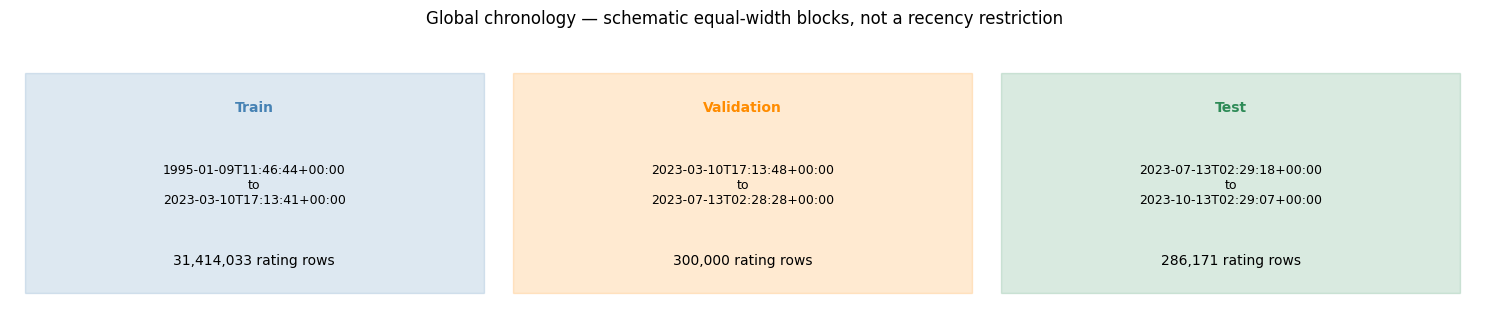

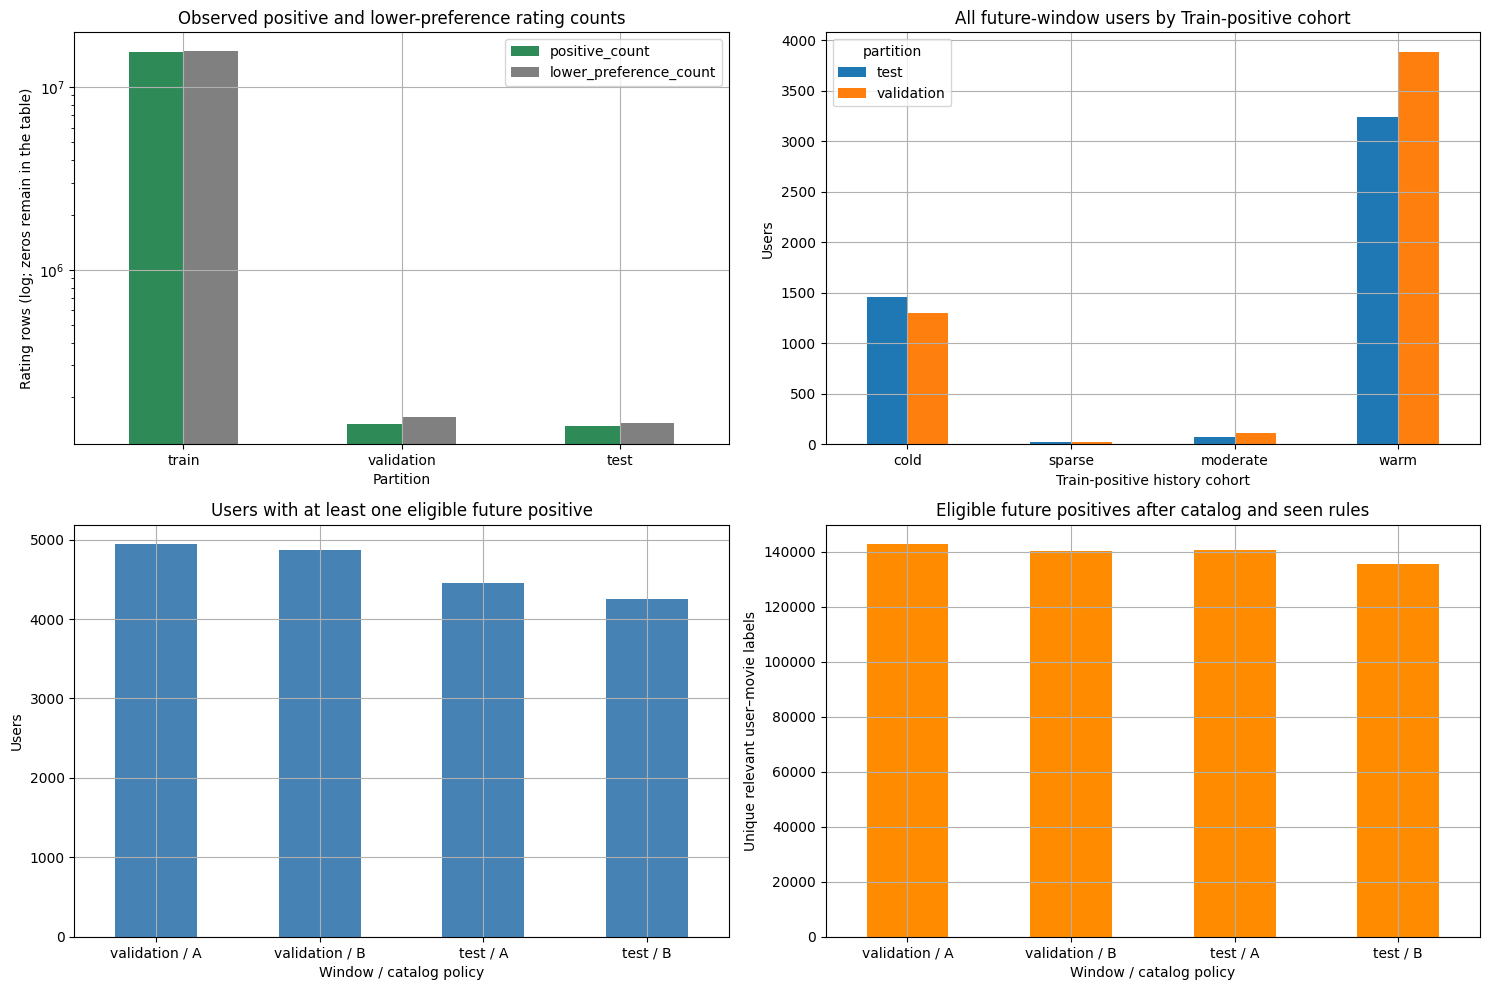

In [10]:
split_timeline_fig, split_timeline_axis = plt.subplots(figsize=(15, 3.4))
split_colors = {'train': 'steelblue', 'validation': 'darkorange', 'test': 'seagreen'}
for position, name in enumerate(PARTITIONS):
    row = partition_statistics.loc[partition_statistics['partition'].eq(name)].iloc[0]
    split_timeline_axis.add_patch(Rectangle((position, .1), .94, .8, color=split_colors[name], alpha=.18))
    split_timeline_axis.text(position + .47, .76, name.title(), ha='center', weight='bold', color=split_colors[name])
    split_timeline_axis.text(position + .47, .49,
        f'{row["min_utc"]}\nto\n{row["max_utc"]}', ha='center', va='center', fontsize=9)
    split_timeline_axis.text(position + .47, .20, f'{int(row["interactions"]):,} rating rows', ha='center')
split_timeline_axis.set(xlim=(-.03, 2.98), ylim=(0, 1.05), title='Global chronology — schematic equal-width blocks, not a recency restriction')
split_timeline_axis.axis('off')
split_timeline_fig.tight_layout()
plt.show()

split_diagnostic_fig, split_diagnostic_axes = plt.subplots(2, 2, figsize=(15, 10))
partition_statistics.set_index('partition')[['positive_count', 'lower_preference_count']].plot.bar(
    ax=split_diagnostic_axes[0, 0], rot=0, color=['seagreen', 'gray'])
split_diagnostic_axes[0, 0].set(title='Observed positive and lower-preference rating counts', xlabel='Partition', ylabel='Rating rows')
if partition_statistics[['positive_count', 'lower_preference_count']].to_numpy().max() > 0:
    split_diagnostic_axes[0, 0].set_yscale('log')
    split_diagnostic_axes[0, 0].set_ylabel('Rating rows (log; zeros remain in the table)')
user_cohort_summary.pivot(index='positive_history_cohort', columns='partition', values='window_users').reindex(
    ['cold', 'sparse', 'moderate', 'warm']).plot.bar(ax=split_diagnostic_axes[0, 1], rot=0)
split_diagnostic_axes[0, 1].set(title='All future-window users by Train-positive cohort', xlabel='Train-positive history cohort', ylabel='Users')
catalog_policy_coverage.assign(label=lambda f: f['partition'] + ' / ' + f['policy']).set_index('label')[
    'eligible_evaluation_users'].plot.bar(ax=split_diagnostic_axes[1, 0], rot=0, color='steelblue')
split_diagnostic_axes[1, 0].set(title='Users with at least one eligible future positive', xlabel='Window / catalog policy', ylabel='Users')
catalog_policy_coverage.assign(label=lambda f: f['partition'] + ' / ' + f['policy']).set_index('label')[
    'eligible_positive_rows'].plot.bar(ax=split_diagnostic_axes[1, 1], rot=0, color='darkorange')
split_diagnostic_axes[1, 1].set(title='Eligible future positives after catalog and seen rules', xlabel='Window / catalog policy', ylabel='Unique relevant user–movie labels')
split_diagnostic_fig.tight_layout()
plt.show()


## 11. Final handoff and downstream contract
Use the same manifest, cohort masks, and catalog policy for all retrieval/ranking comparisons.
`train.parquet` contains all historical ratings, including low-preference observations, and defines the only allowed
training histories for both future windows. Any user-specific recommendation set must exclude every Train-rated item.
The stored item table is a global catalog policy; subtract the user's Train seen set at retrieval/scoring time.
The eligibility table contains label-side masks for evaluation selection, not feature engineering.
A lower rating is an observed lower preference; an unrated movie is not a verified negative.

A held-out rating is a future submission, not necessarily a future watch. Closely related burst submissions can affect
label dependence without automatically being temporal leakage. Exposure/selection bias and uncertain watch times remain
separate limitations. No result here approves a rolling-history evaluation, a separate Rank Train window, or a change to v1.


In [11]:
print(artifact_status)
print('Protocol:', split_manifest['protocol_version'], '| source version:', split_manifest['dataset']['version'])
print('Test UTC interval:', boundary_report['test_start_utc'], 'through', boundary_report['test_end_utc'], '(inclusive)')
print('Validation UTC interval:', boundary_report['validation_start_utc'], 'through', boundary_report['test_start_utc'], '(upper bound exclusive)')
print('Train: complete observed history strictly before', boundary_report['validation_start_utc'])
print('Rows:', split_manifest['row_counts'])
print('All validation checks passed:', split_manifest['validation_results']['all_passed'])
for split_output_name in sorted(EXPECTED_ARTIFACTS):
    print(SPLIT_DIR / split_output_name)
print('No Rank Train partition, model training, downloads, or EDA modifications were performed.')
print('Use validation_* and test_* fields only for labels/population masks. Freeze all model/history features at Train.')


Created and fully validated
Protocol: v1 | source version: ratings-sha256:91159850e41ee59c86231165a688709647e2726cab2e7ba9faf04001bd5261ee
Test UTC interval: 2023-07-13T02:29:07+00:00 through 2023-10-13T02:29:07+00:00 (inclusive)
Validation UTC interval: 2023-03-10T17:13:48+00:00 through 2023-07-13T02:29:07+00:00 (upper bound exclusive)
Train: complete observed history strictly before 2023-03-10T17:13:48+00:00
Rows: {'original': 32000204, 'train': 31414033, 'validation': 300000, 'test': 286171}
All validation checks passed: True
/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1/item_eligibility.parquet
/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1/split_manifest.json
/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1/test.parquet
/content/drive/MyDrive/Colab Notebooks/personal_projects/movielens_hybrid_recsys/data/splits/v1/train.parquet
/content/